# Dijkstra: program sederhana, visualisasi, dan runtime
**Hijir Ismail — Algoritma Komputasi**

Dijkstra adalah fokus utama. Bellman–Ford dan A* hanya pembanding. Data, versi linear, tie-breaking, heuristic, dan metode benchmark mengikuti laporan revisi. Bobot kampus adalah meter ilustratif.

Jalankan sel dari atas ke bawah (**Run All**). Angka pengukuran baru akan berbeda dari laporan karena perangkat dan beban sistem berbeda. Data pengukuran laporan disediakan terpisah agar tidak dianggap sebagai hasil komputer kamu.

In [1]:
from pathlib import Path
import time, statistics, random, platform, json
import pandas as pd
import matplotlib.pyplot as plt
from algoritma import dijkstra, bellman_ford, path, graph
import benchmark_kampus as bk

HASIL = Path("hasil_jupyter")
HASIL.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Python:", platform.python_version(), "| Sistem:", platform.platform())

Python: 3.11.9 | Sistem: Windows-10-10.0.26300-SP0


## 1. Data studi kasus
Enam simpul, delapan ruas tidak berarah. Satu ruas disimpan dua kali dalam adjacency list, sehingga terdapat **16 entri tetangga**. Indeks mengikuti laporan.

In [2]:
nama = ["Rektorat", "Perpustakaan", "Laboratorium", "Kantin", "Kelas", "Parkiran"]
ruas = [(0,1,400), (1,2,300), (0,2,500), (0,3,200),
        (3,4,300), (2,4,400), (3,5,600), (4,5,200)]
graf = [[] for _ in nama]
for u, v, w in ruas:
    graf[u].append((v, w))
    graf[v].append((u, w))
for baris in graf:
    baris.sort()
pd.DataFrame([(nama[u], nama[v], w) for u,v,w in ruas],
             columns=["Dari", "Ke", "Bobot (m ilustratif)"])

,Dari,Ke,Bobot (m ilustratif)
0,Rektorat,Perpustakaan,400
1,Perpustakaan,Laboratorium,300
2,Rektorat,Laboratorium,500
3,Rektorat,Kantin,200
4,Kantin,Kelas,300
5,Laboratorium,Kelas,400
6,Kantin,Parkiran,600
7,Kelas,Parkiran,200


## 2. Rumus dan program utama Dijkstra
- $d[v]$: biaya terbaik dari sumber ke simpul $v$ yang sudah ditemukan.
- $w(u,v)$: bobot ruas dari $u$ ke $v$.
- $S$: kumpulan simpul yang sudah final (`done=True`).
- `prev[v]`: pendahulu simpul $v$, untuk menyusun rute.

**Inisialisasi:** $d[s]=0$ dan $d[v]=\infty$ untuk $v\ne s$.

**Pilih minimum:** $u=\arg\min_{v\notin S}d[v]$. Pilih berdasarkan total biaya dari sumber.

**Relaxation:** $d[v]\leftarrow\min(d[v],d[u]+w(u,v))$. Bila kandidat lebih kecil, perbarui `d[v]` dan `prev[v]=u`.

Contoh: biaya ke Kelas 500, bobot Kelas–Parkiran 200. Kandidat Parkiran $500+200=700$, lebih kecil dari nilai lama 800: simpan 700 dan pendahulu Kelas.

Bobot harus non-negatif agar finalisasi Dijkstra benar. Program memakai minimum linear, bukan heap. Sel berikut menampilkan kode utama yang benar-benar digunakan.

In [3]:
import inspect
print(inspect.getsource(dijkstra))
jarak, pendahulu, langkah = dijkstra(graf, 0, trace=True)
rute = path(pendahulu, 0, 5)
assert jarak == [0,400,500,200,500,700]
assert rute == [0,3,4,5]
print("Rute:", " → ".join(nama[v] for v in rute))
print("Biaya:", jarak[5], "meter ilustratif")

def dijkstra(g, s, trace=False):
    n=len(g); d=[inf]*n; prev=[None]*n; done=[False]*n; d[s]=0; steps=[]
    for _ in range(n):
        u=None
        for v in range(n):
            if not done[v] and (u is None or d[v]<d[u]): u=v
        if u is None or d[u]==inf: break
        done[u]=True
        for v,w in g[u]:
            if not done[v] and d[u]+w<d[v]:
                d[v]=d[u]+w; prev[v]=u
        if trace: steps.append((u,d.copy(),prev.copy()))
    return d,prev,steps

Rute: Rektorat → Kantin → Kelas → Parkiran
Biaya: 700 meter ilustratif


## 3. Tabel langkah Dijkstra
Setiap baris berisi jarak **setelah relaxation** simpul terpilih. Dua simpul berjarak sama dipilih menurut indeks terkecil. Nilai ∞ berarti belum ditemukan lintasan.

In [4]:
tabel = pd.DataFrame([[0,float("inf"),float("inf"),float("inf"),float("inf"),float("inf")]]
                     + [d for u,d,pr in langkah], columns=nama)
tabel.insert(0, "Simpul dipilih", ["Awal"] + [nama[u] for u,d,pr in langkah])
display(tabel)
tabel.to_csv(HASIL / "langkah_dijkstra.csv", index=False)

,Simpul dipilih,Rektorat,Perpustakaan,Laboratorium,Kantin,Kelas,Parkiran
0,Awal,0,inf,inf,inf,inf,inf
1,Rektorat,0,400.0,500.0,200.0,inf,inf
2,Kantin,0,400.0,500.0,200.0,500.0,800.0
3,Perpustakaan,0,400.0,500.0,200.0,500.0,800.0
4,Laboratorium,0,400.0,500.0,200.0,500.0,800.0
5,Kelas,0,400.0,500.0,200.0,500.0,700.0
6,Parkiran,0,400.0,500.0,200.0,500.0,700.0


## 4. Visualisasi graf dan langkah
Biru: simpul yang sudah final. Jingga: simpul yang diproses pada langkah itu. Garis biru tebal: rute hasil. Posisi gambar hanya untuk tata letak dan **bukan** koordinat heuristic A*.

Ubah `tahap` dari **0 sampai 6** lalu jalankan kembali sel visualisasi langkah.

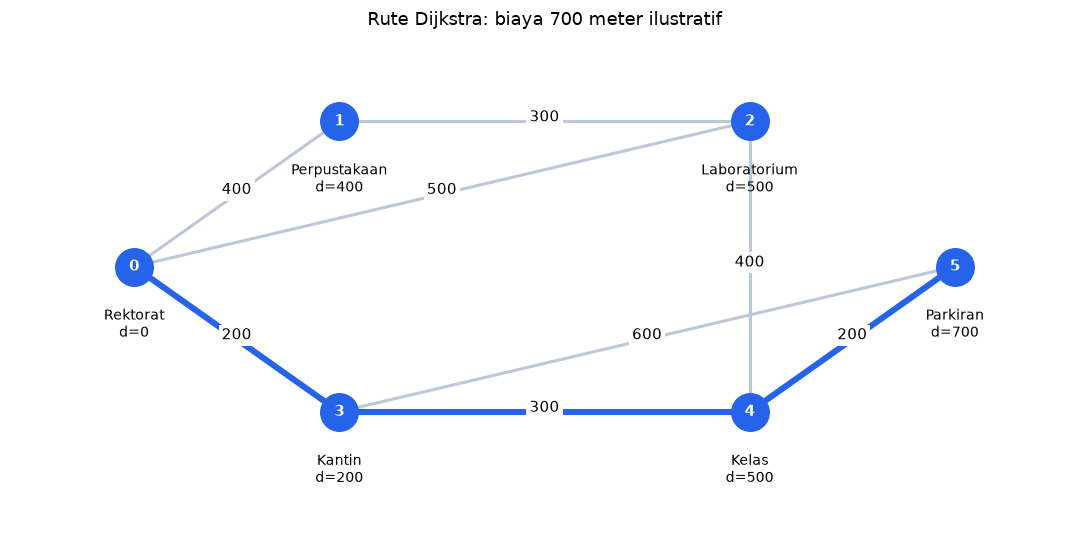

In [5]:
posisi = [(0,1), (1,2), (3,2), (1,0), (3,0), (4,1)]
def gambar(ax, tahap=None, jalur=None):
    d = jarak if tahap is None else ([0]+[float("inf")]*5 if tahap==0 else langkah[tahap-1][1])
    final = set(range(6)) if tahap is None else {u for u,_,_ in langkah[:tahap]}
    aktif = None if tahap in (None,0) else langkah[tahap-1][0]
    sisi_rute = set() if not jalur else {frozenset((u,v)) for u,v in zip(jalur,jalur[1:])}
    for u,v,w in ruas:
        x,y=posisi[u]; xx,yy=posisi[v]
        cocok=frozenset((u,v)) in sisi_rute
        ax.plot([x,xx],[y,yy],color="#2563eb" if cocok else "#bcc8d8",lw=4 if cocok else 2,zorder=1)
        ax.text((x+xx)/2,(y+yy)/2,str(w),ha="center",bbox=dict(facecolor="white",edgecolor="none",pad=2),zorder=4)
    for v,(x,y) in enumerate(posisi):
        warna="#f59e0b" if v==aktif else ("#2563eb" if v in final else "#94a3b8")
        ax.scatter(x,y,s=600,color=warna,zorder=3)
        ax.text(x,y,str(v),ha="center",va="center",color="white",weight="bold",zorder=4)
        nilai="∞" if d[v]==float("inf") else str(d[v])
        ax.text(x,y-.28,nama[v]+"\nd="+nilai,ha="center",va="top",fontsize=9)
    ax.set(xlim=(-.6,4.6),ylim=(-.8,2.6));ax.axis("off")
fig, ax = plt.subplots(figsize=(10,5))
gambar(ax, jalur=rute); ax.set_title("Rute Dijkstra: biaya 700 meter ilustratif")
plt.tight_layout(); fig.savefig(HASIL / "rute_dijkstra.png", bbox_inches="tight");plt.show()

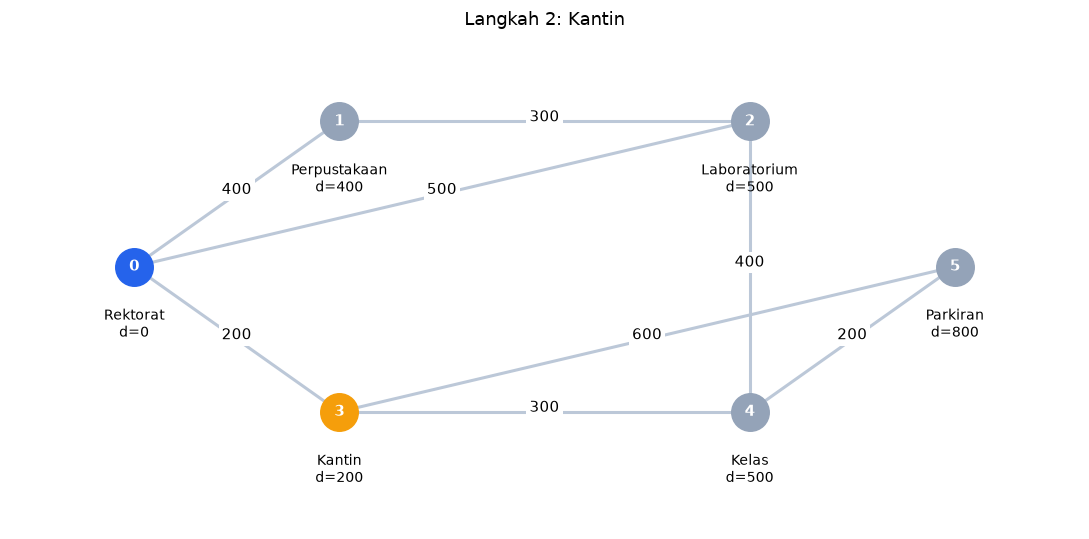

In [6]:
tahap = 2  # Ganti 0–6: 2 berarti setelah Kantin diproses.
assert 0 <= tahap <= 6
fig, ax = plt.subplots(figsize=(10,5))
gambar(ax, tahap=tahap)
ax.set_title("Awal" if tahap==0 else f"Langkah {tahap}: {nama[langkah[tahap-1][0]]}")
plt.tight_layout();plt.show()

## 5. Pembanding Bellman–Ford dan A*
**Bellman–Ford** memakai relaxation yang sama, tetapi memeriksa seluruh busur hingga paling banyak $n-1$ pass; berhenti lebih awal jika tidak ada perubahan. Satu pass tambahan mendeteksi siklus negatif terjangkau.

Walau $w(A,B)=w(B,A)$, kandidat $d[A]+w(A,B)$ dan $d[B]+w(B,A)$ berbeda ketika biaya ke pangkal berbeda. Pemeriksaan balik adalah arah pemeriksaan, bukan perjalanan mundur.

**A*** memakai $f(v)=g(v)+h(v)$, dengan $g(v)$ biaya dari sumber dan $h(v)$ perkiraan sisa biaya. Laporan menggunakan $h(v)=|x(v)-x(t)|$, dengan koordinat ilustratif $x=[0,100,250,200,500,700]$. Ke Parkiran: $h=[700,600,450,500,200,0]$.

Consistency: $h(u)\le w(u,v)+h(v)$ untuk setiap busur, dan $h(t)=0$. Heuristic ini konsisten pada seluruh ruas kampus. A* linear pada paket ini memerlukan consistency agar simpul tertutup tidak perlu dibuka ulang.

Dijkstra memilih 6 simpul; A* memilih 4. Lebih sedikit simpul tidak menjamin runtime lebih cepat karena heuristic juga membutuhkan perhitungan.

In [7]:
for s in range(6):
    for t in range(6):
        h = [abs(x-bk.X[t]) for x in bk.X]
        assert h[t]==0 and all(h[u] <= w+h[v] for u in range(6) for v,w in graf[u])
        assert bk.greedy(graf,s,t)==bk.bellman(graf,s,t)==bk.astar(graf,s,t)
print("Lulus: biaya seluruh 36 pasangan sumber–tujuan sama; heuristic konsisten.")
display(pd.DataFrame({"Algoritma":["Dijkstra tujuan","Bellman–Ford","A* tujuan"],
 "Biaya Parkiran":[700,700,700], "Simpul dipilih":[6,"Tidak memilih minimum",4],
 "Posisi dipindai":[36,"Tidak memilih minimum",24], "Entri sisi diperiksa":[14,48,9],
 "Pembaruan berhasil":[6,7,6]}))
print("Counter tabel mengikuti laporan, bukan hasil interval benchmark.")

Lulus: biaya seluruh 36 pasangan sumber–tujuan sama; heuristic konsisten.


,Algoritma,Biaya Parkiran,Simpul dipilih,Posisi dipindai,Entri sisi diperiksa,Pembaruan berhasil
0,Dijkstra tujuan,700,6,36,14,6
1,Bellman–Ford,700,Tidak memilih minimum,Tidak memilih minimum,48,7
2,A* tujuan,700,4,24,9,6


Counter tabel mengikuti laporan, bukan hasil interval benchmark.


## 6. Runtime kampus: ketiga algoritma
Metode persis seperti laporan: 1.000 pemanasan; 7 batch × 10.000 pencarian; urutan diacak dengan seed 20261009. Biaya inisialisasi, pembuatan heuristic A*, dan edge list Bellman–Ford ikut dihitung. Tidak ada plotting, trace, counter, atau rekonstruksi rute dalam interval waktu.

$T_i=(t_{akhir}-t_{awal})/(10.000\times1.000)$ menghasilkan µs/pencarian karena timer memakai ns.

$\bar T=\frac{1}{k}\sum T_i$, dan $SD=\sqrt{\frac{\sum(T_i-\bar T)^2}{k-1}}$, dengan $k=7$. SD dihitung **antar-rerata batch**, bukan antar-pencarian.

Laporan: Dijkstra 2,556 ± 0,144 µs; Bellman–Ford 3,973 ± 0,073 µs; A* 2,625 ± 0,065 µs. Sel ini mengukur ulang, tidak menyalin angka tersebut.

,Algoritma,Mean µs,SD µs,Mean laporan µs
0,Dijkstra,4.084683,0.337667,2.556325
1,Bellman–Ford,6.147640,0.366443,3.973085
2,A*,3.950756,0.153930,2.625251


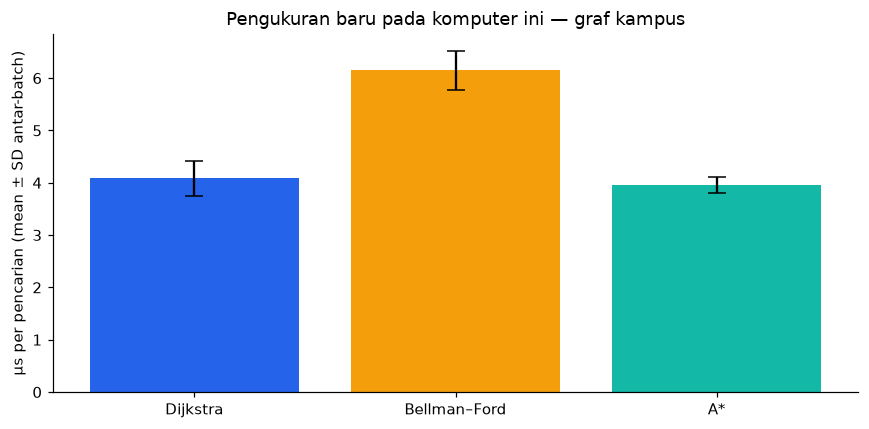

In [8]:
fungsi = {"Dijkstra":bk.greedy, "Bellman–Ford":bk.bellman, "A*":bk.astar}
for fn in fungsi.values():
    for _ in range(1000): fn(graf,0,5)
sampel = {k:[] for k in fungsi}
acak = random.Random(20261009)
for batch in range(7):
    urutan=list(fungsi); acak.shuffle(urutan)
    for label in urutan:
        mulai=time.perf_counter_ns()
        for _ in range(10000): fungsi[label](graf,0,5)
        sampel[label].append((time.perf_counter_ns()-mulai)/10000/1000)
aktual=pd.DataFrame([{"Algoritma":a,"Mean µs":statistics.mean(v),"SD µs":statistics.stdev(v)} for a,v in sampel.items()])
acuan=json.loads(Path("runtime_kampus_laporan.json").read_text())
aktual["Mean laporan µs"]=[acuan["summary"][a]["mean"] for a in aktual["Algoritma"]]
display(aktual)
aktual.to_csv(HASIL / "runtime_kampus.csv",index=False)
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(aktual["Algoritma"],aktual["Mean µs"],yerr=aktual["SD µs"],capsize=6,color=["#2563eb","#f59e0b","#14b8a6"])
ax.set_ylabel("µs per pencarian (mean ± SD antar-batch)");ax.set_title("Pengukuran baru pada komputer ini — graf kampus")
plt.tight_layout();fig.savefig(HASIL / "runtime_kampus.png");plt.show()

## 7. Runtime pertumbuhan SSSP: Dijkstra dan Bellman–Ford
Ini pengujian **semua jarak dari satu sumber**, berbeda dari pencarian tujuan pada sel sebelumnya. Sesuai laporan: n=100,200,400,800,1600; m=3n; bobot 1–100; seed 20261006+n; 1 pemanasan dan 5 pengukuran per algoritma. Pembuatan graf dan pemeriksaan kebenaran berada di luar timer.

A* tidak ditambahkan ke grafik ini karena laporan memakai A* untuk satu tujuan, bukan seluruh jarak. Perbandingan A* ada pada pengujian kampus di atas.

,n,m,algorithm,mean_ms,std_ms
0,100,300,Dijkstra linear,0.54694,0.038621
1,100,300,Bellman-Ford early stop,0.32512,0.051209
2,200,600,Dijkstra linear,4.18784,3.250382
3,200,600,Bellman-Ford early stop,0.96032,0.018587
4,400,1200,Dijkstra linear,7.39328,1.954587
5,400,1200,Bellman-Ford early stop,1.52216,0.131787
6,800,2400,Dijkstra linear,24.01346,1.180358
7,800,2400,Bellman-Ford early stop,4.14284,0.350269
8,1600,4800,Dijkstra linear,96.05284,1.611729
9,1600,4800,Bellman-Ford early stop,10.47438,0.508766


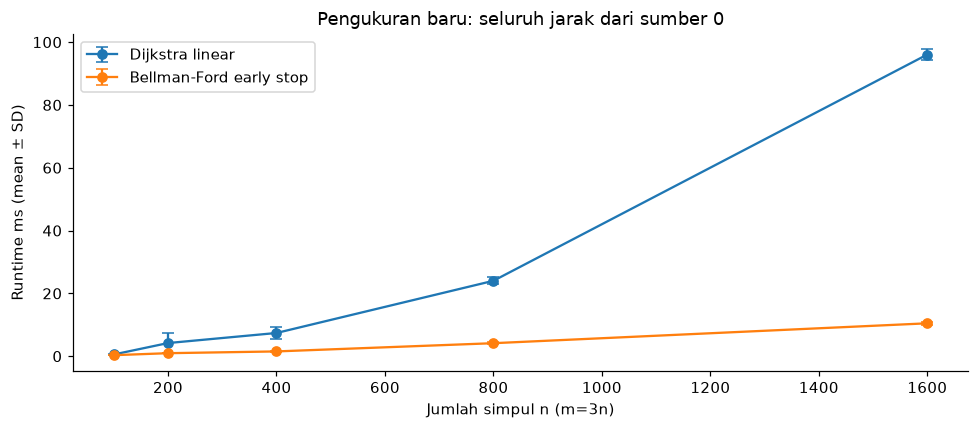

Acuan hasil laporan, tidak diukur ulang oleh tabel berikut:


,n,m,algorithm,mean_ms,std_ms
0,100,300,Dijkstra linear,0.292580,0.021665
1,100,300,Bellman-Ford early stop,0.201007,0.007799
2,200,600,Dijkstra linear,1.258232,0.087504
3,200,600,Bellman-Ford early stop,0.454151,0.053860
4,400,1200,Dijkstra linear,4.157459,0.148632
5,400,1200,Bellman-Ford early stop,1.275650,0.072976
6,800,2400,Dijkstra linear,20.229072,0.651414
7,800,2400,Bellman-Ford early stop,2.953210,0.178645
8,1600,4800,Dijkstra linear,70.627188,1.418949
9,1600,4800,Bellman-Ford early stop,8.106238,0.787233


In [9]:
rekap=[]; mentah=[]
for n in [100,200,400,800,1600]:
    g=graph(n,20261006+n)
    assert dijkstra(g,0)[0]==bellman_ford(g,0)
    for label,fn in [("Dijkstra linear",lambda:dijkstra(g,0)),
                     ("Bellman-Ford early stop",lambda:bellman_ford(g,0))]:
        fn(); waktu=[]
        for run in range(5):
            awal=time.perf_counter_ns();fn();ms=(time.perf_counter_ns()-awal)/1e6
            waktu.append(ms);mentah.append([n,3*n,label,run+1,ms])
        rekap.append([n,3*n,label,statistics.mean(waktu),statistics.stdev(waktu)])
sssp=pd.DataFrame(rekap,columns=["n","m","algorithm","mean_ms","std_ms"])
display(sssp)
sssp.to_csv(HASIL / "runtime_sssp_ringkasan.csv",index=False)
pd.DataFrame(mentah,columns=["n","m","algorithm","run","ms"]).to_csv(HASIL / "runtime_sssp_mentah.csv",index=False)
fig,ax=plt.subplots(figsize=(9,4))
for a in sssp.algorithm.unique():
    r=sssp[sssp.algorithm==a]
    ax.errorbar(r.n,r.mean_ms,yerr=r.std_ms,marker="o",capsize=4,label=a)
ax.set(xlabel="Jumlah simpul n (m=3n)",ylabel="Runtime ms (mean ± SD)",title="Pengukuran baru: seluruh jarak dari sumber 0")
ax.legend();plt.tight_layout();fig.savefig(HASIL / "runtime_sssp.png");plt.show()
laporan=pd.DataFrame(json.loads(Path("runtime_sssp_laporan.json").read_text())["rows"])
print("Acuan hasil laporan, tidak diukur ulang oleh tabel berikut:")
display(laporan)

## 8. Kompleksitas dan kesimpulan
Untuk graf terhubung, Dijkstra linear SSSP memindai **n² posisi** dan membaca **2m entri tetangga** pada graf tidak berarah: $\Theta(n^2+m)$. Pada graf sederhana, menjadi $\Theta(n^2)$. Ruang bantu tanpa trace: $O(n)$; penyimpanan graf: $\Theta(n+m)$.

Pada mode tujuan: $O(n+rn+q)$, dengan r jumlah simpul yang dipilih dan q entri tetangga yang diperiksa. Kasus kampus: Dijkstra r=6,q=14; A* r=4,q=9. A* mempunyai tambahan biaya heuristic. Bellman–Ford batas terburuk $O(nm)$, tetapi early stopping dapat mengurangi pekerjaan aktual.

Trace membuat salinan array per langkah, jadi jangan mengukur runtime dengan trace jika ingin mengikuti benchmark laporan. A* dan Bellman–Ford hanya memperjelas karakteristik Dijkstra; hasil waktu tidak boleh digeneralisasi ke semua graf.

Semua gambar dan CSV tersimpan di folder **hasil_jupyter**. Rumus biaya lintasan: $C(P)=\sum_{(u,v)\in P}w(u,v)$; rute kampus $200+300+200=700$.